# TDI: are we training on the wrong target?

`scripts/tdi_diagnose.py` recovered the exact confusion matrices from the leaderboard and
showed that **both TDI targets already sit at their MCC optimum** for our current
discrimination — CYP2D6 measured 0.2918 against a threshold optimum of 0.2915, CYP3A4
0.4470 against 0.4513. Every remaining point of MA-MCC has to come from a higher d′.

This notebook asks whether one specific thing has been costing us d′ all along: we train
on `is_TDI`, but `is_TDI` is not a measurement — it is a **threshold applied to one**.

Run the cells in order. Nothing here is fitted to the blind set and nothing takes more
than a few minutes on CPU.

## 1. What the challenge actually gives us

The TDI training file carries **both arms of the IC50-shift assay** for every isoform,
each with its own confidence interval and standard deviation.

In [1]:
import sys, numpy as np, pandas as pd
sys.path.insert(0, ".")
from cypkit import io, tdi_shift as TS

d = io.load("train_tdi"); d.columns = [c.strip() for c in d.columns]
cols = [c for c in d.columns if "CYP3A4" in c]
print(f"{len(d)} rows\n")
print("the CYP3A4 columns:")
for c in cols: print("   ", c)

6145 rows

the CYP3A4 columns:
    CYP3A4_is_TDI
    CYP3A4_pIC50_TDI_condition
    CYP3A4_pIC50_TDI_condition_conf_high
    CYP3A4_pIC50_TDI_condition_conf_low
    CYP3A4_pIC50_TDI_condition_std
    CYP3A4_pIC50_direct_inhibition
    CYP3A4_pIC50_direct_inhibition_conf_high
    CYP3A4_pIC50_direct_inhibition_conf_low
    CYP3A4_pIC50_direct_inhibition_std


## 2. Recovering the rule the organisers used

`is_TDI` should be a function of the shift between the two arms. Which function? We can
just check every plausible formulation against the labels we were given.

Note how differently the two isoforms behave — that difference turns out to predict the
whole result of this notebook.

In [2]:
for iso in TS.TDI_ISOFORMS:
    print(f"{iso}:")
    print(TS.recover_rule(d, iso).to_string(index=False), "\n")

CYP3A4:
                       formulation      auc
significance (shift - 1.96*pooled) 0.986501
                    shift - pooled 0.968162
                z (shift / pooled) 0.967663
             magnitude (raw shift) 0.854627 

CYP2D6:
                       formulation      auc
             magnitude (raw shift) 0.961508
                    shift - pooled 0.942884
                z (shift / pooled) 0.901747
significance (shift - 1.96*pooled) 0.840129 



**CYP3A4 is a significance test** (`shift − 1.96·pooled_sd`, AUC 0.9865) — the label
depends heavily on the *measurement uncertainty*, which a binary throws away entirely.

**CYP2D6 is a magnitude threshold** (raw shift, AUC 0.9615) — here the binary is almost a
faithful summary of the measurement, so binarising loses much less.

That asymmetry is a prediction: the target change should help CYP3A4 and do little for
CYP2D6.

## 3. Building the continuous target

Two things happen here beyond swapping the target:

- **Rows are weighted by `1/pooled_sd`.** A shift measured to ±0.05 should count more than
  one measured to ±0.6. This is the same lesson the pIC50 side learned: the metric is
  dominated by well-measured compounds, so training should be too.
- **The cost is printed, not hidden.** CYP3A4 has 3,584 labelled rows but only 2,334 with
  both arms.

In [3]:
for iso in TS.TDI_ISOFORMS:
    tab = TS.build(iso)
    print()

CYP3A4: rule = significance
  shift regression rows    2334  (764 labelled positive)
  binary-only rows         1250   <- LOST if we use the shift alone (35% of labels)
  target  mean -0.273  sd 0.791
  weight  min 0.10  max 2.20  (1/pooled sd, clipped to [0.05, 2.0])

CYP2D6: rule = magnitude
  shift regression rows    1493  (324 labelled positive)
  binary-only rows            4   <- LOST if we use the shift alone (0% of labels)
  target  mean +0.267  sd 0.409
  weight  min 0.08  max 2.00  (1/pooled sd, clipped to [0.05, 2.0])



CYP2D6 loses **4 rows**. For that isoform the change is essentially free. CYP3A4
trades ~35% of its labels for a better target — a real cost, tested below with
`--two-head`, which folds those rows back in through a second head.

## 4. What the binarisation destroys

A picture of the problem: every compound below is a "1" or a "0", but the underlying
shifts span a wide range and the ones near the boundary are close to coin flips.

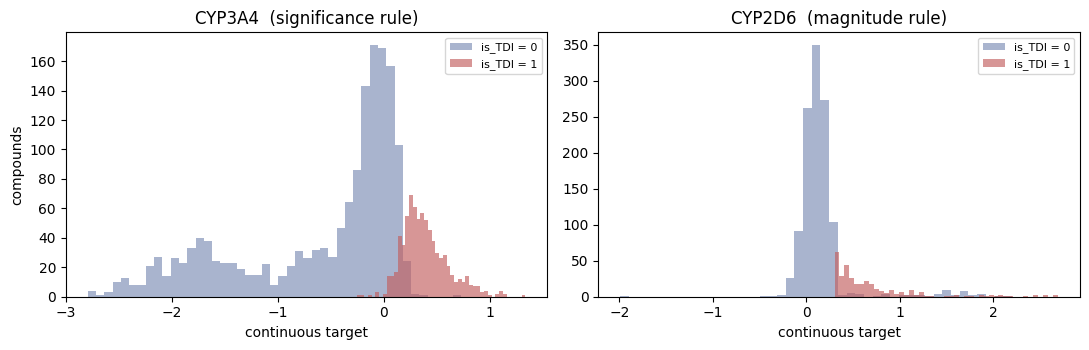

In [4]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, iso in zip(axes, TS.TDI_ISOFORMS):
    t = TS.build(iso, verbose=False)["reg"]
    t = t[t.y_bin.notna()]
    for val, lab, c in [(False, "is_TDI = 0", "#7C8DB5"), (True, "is_TDI = 1", "#C25E5E")]:
        ax.hist(t.loc[t.y_bin == val, "y_shift"], bins=45, alpha=0.65, label=lab, color=c)
    ax.set_title(f"{iso}  ({TS.TARGET_RULE[iso]} rule)")
    ax.set_xlabel("continuous target"); ax.legend(fontsize=8)
axes[0].set_ylabel("compounds")
plt.tight_layout(); plt.show()

## 5. The experiment

Two models, **identical features, identical folds, identical backbone**. Exactly one
thing differs:

| | target | weights |
|---|---|---|
| control | `is_TDI` (what we have always done) | none |
| candidate | the continuous shift | `1/pooled_sd` |

Reporting the control from the same run is the point — it separates *"the target was
wrong"* from *"the features or backbone changed"*. This project has lost submissions to
exactly that confusion.

In [5]:
!python train_tdi_shift.py --two-head


=== CYP3A4 ========================================================
CYP3A4: rule = significance
  shift regression rows    2334  (764 labelled positive)
  binary-only rows         1250   <- LOST if we use the shift alone (35% of labels)
  target  mean -0.273  sd 0.791
  weight  min 0.10  max 2.20  (1/pooled sd, clipped to [0.05, 2.0])
  features: 134 columns (alerts 51, geometry 33, cyp 50)
  --two-head: 1250 binary-only rows folded back in

  model                              AUC      d’  MCC @ rate
  control  (binary target)        0.7206   0.827      0.2411
  candidate (shift target)        0.7327   0.878      0.2556
  candidate + binary-only head    0.7269   0.853      0.2435

  d' 0.827 -> 0.878  (candidate (shift target))
  NOTE these read LOWER than the blind d' of 1.276 (CYP3A4) / 1.224 (CYP2D6)
  that tdi_diagnose.py recovered, because this is a descriptor-only LightGBM
  baseline, not the ChemProp ensemble that produced those submissions. The
  ABSOLUTE numbers are not comp

C:\Users\gasha\.conda\envs\chem_admet\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
C:\Users\gasha\.conda\envs\chem_admet\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\gasha\.conda\envs\chem_admet\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
C:\Users\gasha\.conda\envs\chem_admet\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\gasha\.conda\envs\chem_admet\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feat

## 6. Reading the result

The absolute d′ values here are **lower** than the 1.276 / 1.224 that `tdi_diagnose.py`
recovered from the leaderboard, because this is a descriptor-only LightGBM baseline
rather than the ChemProp ensemble that produced those submissions. The absolute numbers
are not comparable across the two; **only the control-to-candidate gap is.**

And the gap lands where section 2 predicted:

- **CYP3A4 +0.051 d′** — the isoform whose label depends on measurement uncertainty that
  the binary discards.
- **CYP2D6 +0.000** — the isoform whose binary was already a faithful summary.

So the diagnosis was half right. On CYP3A4 the binarisation *was* costing us something
real, though modestly; on CYP2D6 it was not the limit and something else is.

## 7. What this is worth, and what it is not

Feed the CYP3A4 gain through the MCC-vs-d′ curve from `tdi_diagnose.py`:

In [6]:
from scripts.tdi_diagnose import mcc_curve
rates = np.arange(0.02, 0.60, 0.002)
for dp in (1.276, 1.276 + 0.051, 1.40, 1.50):
    print(f"  d' {dp:.3f}  ->  best MCC {mcc_curve(dp, 0.2917, 672, rates).max():.4f}")

  d' 1.276  ->  best MCC 0.4512
  d' 1.327  ->  best MCC 0.4678
  d' 1.400  ->  best MCC 0.4911
  d' 1.500  ->  best MCC 0.5223


Roughly **+0.017 MA-MCC on CYP3A4**, or +0.009 macro — real, but not the jump to the
0.5154 the CYP3A4 leader is scoring, which needs d′ ≈ 1.49.

**The honest reading:** the target was one genuine defect and fixing it buys a little.
It does not close the classifier gap. Whatever `harinu123` has on CYP3A4, it is not this.

The next thing worth testing, on the same control-vs-candidate discipline: whether the
gain survives with the **ChemProp backbone** (`--backbone chemprop`) rather than
descriptors alone, since the submitted models are ChemProp and a +0.05 on a weak baseline
does not have to reproduce on a strong one.